# Multi-modality and the agent loop: what they are and why they matter

Two ideas carry this whole programme. **Multi-modality**: the panel can be
sensed in several independent ways, and the *combination* says things no single
sense can. **The agent loop**: observe, believe, choose evidence, act, verify,
finish honestly. This notebook shows each with the smallest experiment that
makes the point, on the same simulator as `quickstart.ipynb`.

| Part | Question | Experiment |
|---|---|---|
| 1 | What is multi-modality? | Five hidden causes, four passive senses: who notices what |
| 2 | Why does it matter? | How many causes remain possible as senses are added |
| 3 | Sensing as an action | An IV sweep separates two causes the passive senses confuse |
| 4 | What is the agent loop? | The loop in fifteen lines, three controllers built on it |
| 5 | Why does it matter? | The three controllers across six worlds, including a surprise |

This notebook is the tutorial behind Section 4 of the plain-language overview,
`output/pdf/Agentic_PV_Overview_Plain_Language_2026-10-30.pdf`: the steps there
are the parts here. The overview calls the series-resistance world a "wiring
fault"; it is the same hidden cause.

Run from the repository root with
`uv run --with jupyter --with matplotlib jupyter lab notebooks/multimodality_and_agent_loop.ipynb`
or `uv run --with matplotlib python notebooks/multimodality_and_agent_loop.py`.
Camera cells need a desktop graphics session and skip themselves otherwise.

In [1]:
import base64
import io
import json
import sys
from pathlib import Path

import matplotlib
if not hasattr(sys, "ps1") and "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

ROOT = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from pv_sim.config import Config, load_config
from pv_sim.contracts import ACTION_ADAPTER, Decision, HypothesisProbability, validate_decision_context
from pv_sim.env import PVEnv
from pv_sim.policies.protocol import PublicBaseline
from pv_sim.policy_runner import PolicyRunner

FIG_DIR = ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(exist_ok=True)


def show(fig, name):
    if matplotlib.get_backend().lower() == "agg":
        fig.savefig(FIG_DIR / f"{name}.png", dpi=110, bbox_inches="tight")
        print(f"saved {FIG_DIR / (name + '.png')}")
    else:
        plt.show()
    plt.close(fig)


def make_config(horizon_s=20.0, **private):
    """pilot.toml with a shorter horizon and overrides of hidden world values."""
    raw = load_config(ROOT / "configs" / "pilot.toml").model_dump(mode="python")
    raw["simulation"]["horizon_s"] = horizon_s
    raw["budgets"]["time_s"] = horizon_s
    raw["private_world"].update(private)
    return Config.model_validate_json(json.dumps(raw, allow_nan=False))


class Session:
    """A thin hand-driven wrapper: numbers the actions and keeps the history."""

    def __init__(self, config, render):
        self.env = PVEnv(config, enable_rendering=render)
        self.task, first = self.env.reset(seed=1)
        self.history = [first]
        self.next_id = 1

    def do(self, kind, **fields):
        fields.setdefault("timeout_s", 8.0)
        observation = self.env.step({"schema_version": "1.0", "action_id": self.next_id, "kind": kind, **fields})
        self.next_id += 1
        self.history.append(observation)
        return observation

    def close(self):
        self.env.close()


def series(history, channel):
    return sorted((s.t_capture_s, s.value) for o in history for s in o.scalars
                  if s.channel == channel and s.validity == "valid")


def matched_vi(history):
    v = dict(series(history, "voltage_v"))
    i = dict(series(history, "current_a"))
    return sorted((t, v[t], i[t]) for t in v.keys() & i.keys())


def recent(history, channel, window_s=0.5):
    t_end = history[-1].t_deliver_s
    if channel == "power_w":
        values = [v * i for t, v, i in matched_vi(history) if t >= t_end - window_s]
    else:
        values = [y for t, y in series(history, channel) if t >= t_end - window_s]
    return float(np.mean(values)) if values else None


def brightness(history):
    frames = [f for o in history for f in o.rgb if f.validity == "valid"]
    if not frames:
        return None
    return float(np.array(Image.open(io.BytesIO(base64.b64decode(frames[-1].png_base64)))).mean())


def rendering_available():
    try:
        s = Session(make_config(), render=True)
        try:
            return bool(s.do("capture_rgb", timeout_s=2.0).rgb)
        finally:
            s.close()
    except Exception as exc:  # noqa: BLE001
        print(f"rendering unavailable ({type(exc).__name__}); the camera column is dropped")
        return False


RENDER = rendering_available()
print("camera available:", RENDER)

camera available: True


## Part 1. What is multi-modality?

A modality is an independent way of sensing the same world. This panel has
five, and they differ in what they measure, how fast they arrive, and what
they cost:

| Modality | Measures | Rate | Latency | Cost | Passive or active |
|---|---|---|---|---|---|
| Electrical (V, I) | the panel's output at the present operating point | 10 Hz | 20 ms | free | passive, but *where* on the curve you sit is a choice |
| Reference irradiance | light arriving next to the panel | 10 Hz | 20 ms | free | passive |
| Temperature | module temperature | 10 Hz | 20 ms | free | passive |
| Camera | an image of the panel and its surroundings | on request, max 2 Hz | 100 ms | 0.1 per frame, plus time to move | active |
| IV probe | current at chosen voltages | on request | seconds | 0.2 per point, plus lost energy | active |

**The experiment.** Five worlds, each with one hidden cause. In every world we
run the same passive protocol: one camera frame, one second of listening. Then
we ask each modality: did you change relative to the clean world?

In [2]:
WORLDS = {
    "clean":            {},
    "cloud":            {"dni_w_m2": 300.0},
    "shaded cell":      {"transmission": [1, 1, 0.3, 1, 1, 1, 1, 1]},
    "series resistance": {"series_resistance_ohm": 1.0},
    "hot panel":        {"initial_temperature_c": 60.0, "ambient_temperature_c": 40.0},
}
TRUTH = {"clean": None, "cloud": "source_change", "shaded cell": "transmission_change",
         "series resistance": "electrical_change", "hot panel": "thermal_change"}
MODALITIES = ["power_w", "reference_w_m2", "temperature_c"] + (["camera"] if RENDER else [])
LABELS = {"power_w": "electrical\n(power)", "reference_w_m2": "reference\nirradiance",
          "temperature_c": "temperature", "camera": "camera\n(brightness)"}
SHORT = {"power_w": "power", "reference_w_m2": "reference", "temperature_c": "temperature", "camera": "camera"}


def passive_look(config):
    """The passive protocol: a frame (if available), one second of listening."""
    s = Session(config, render=RENDER)
    try:
        if RENDER:
            s.do("capture_rgb", timeout_s=2.0)
        s.do("wait", duration_s=1.0, timeout_s=1.5)
        reading = {m: recent(s.history, m) for m in MODALITIES if m != "camera"}
        if RENDER:
            reading["camera"] = brightness(s.history)
            frame = [f for o in s.history for f in o.rgb][-1]
            reading["image"] = np.array(Image.open(io.BytesIO(base64.b64decode(frame.png_base64))))
        return reading
    finally:
        s.close()


readings = {name: passive_look(make_config(**private)) for name, private in WORLDS.items()}
base = readings["clean"]
change = np.array([[100 * (readings[w][m] - base[m]) / base[m] for m in MODALITIES] for w in WORLDS])

print(f"{'world':20s}" + "".join(f"{m:>18s}" for m in MODALITIES))
for w, row in zip(WORLDS, change):
    print(f"{w:20s}" + "".join(f"{x:+17.1f}%" for x in row))

world                          power_w    reference_w_m2     temperature_c            camera
clean                            +0.0%             +0.0%             +0.0%             +0.0%
cloud                           -56.6%            -55.6%             -4.2%            -56.0%
shaded cell                     -16.4%             +0.0%             -0.6%             +0.0%
series resistance               -16.0%             +0.0%             +0.0%             +0.0%
hot panel                        -6.5%             +0.0%           +127.6%             +0.0%


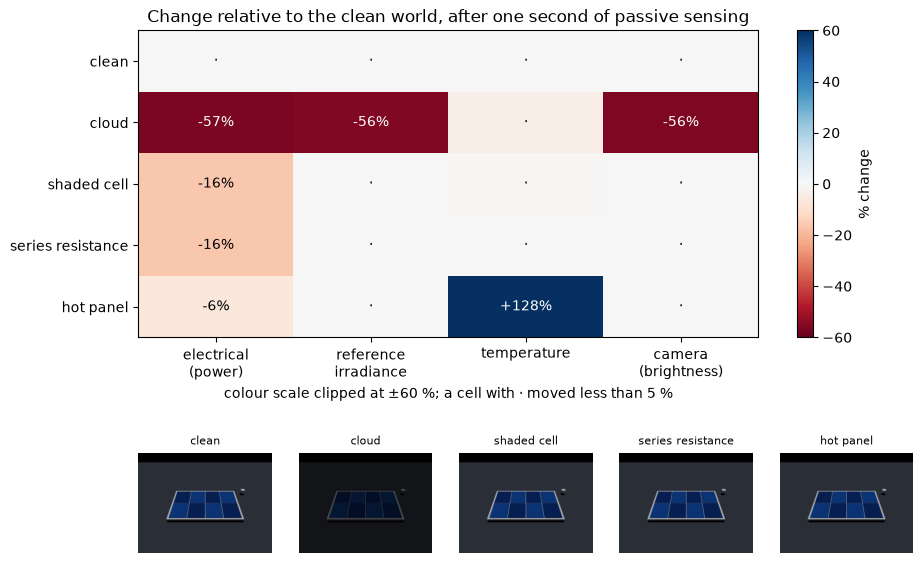

In [3]:
CHANGED = 5.0   # percent: smaller moves are treated as "no change"

fig = plt.figure(figsize=(10, 7 if RENDER else 3.6))
grid = fig.add_gridspec(2 if RENDER else 1, 1, height_ratios=[3, 1.3] if RENDER else [1], hspace=0.45)
ax = fig.add_subplot(grid[0])
limit = 60   # colour scale clips; the numbers in the cells are exact
im = ax.imshow(np.clip(change, -limit, limit), cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(len(MODALITIES)), [LABELS[m] for m in MODALITIES])
ax.set_yticks(range(len(WORLDS)), list(WORLDS))
for r, row in enumerate(change):
    for c, x in enumerate(row):
        ax.text(c, r, f"{x:+.0f}%" if abs(x) >= CHANGED else "·", ha="center", va="center",
                color="white" if abs(x) > limit / 2 else "black", fontsize=10)
ax.set_xlabel(f"colour scale clipped at ±{limit} %; a cell with · moved less than {CHANGED:.0f} %")
ax.set_title("Change relative to the clean world, after one second of passive sensing")
fig.colorbar(im, ax=ax, label="% change")
if RENDER:
    inner = grid[1].subgridspec(1, len(WORLDS))
    for k, w in enumerate(WORLDS):
        a = fig.add_subplot(inner[k])
        a.imshow(readings[w]["image"])
        a.set_title(w, fontsize=8)
        a.axis("off")
show(fig, "20_signatures")

**Reading the matrix.** Power drops in every faulty world, so the electrical
channel is a good *alarm* and a useless *diagnosis*. The reference sensor moves
only under the cloud. The temperature sensor moves only for the hot panel. The
camera, in this build, sees the cloud and nothing else: the cells are drawn
with fixed colours, so a shaded cell looks exactly like a clean one. (Making
shading visible is the first step of the module's minimal goal.)

Two worlds, the shaded cell and the series resistance, have the **same passive
signature**: power down, everything else unchanged. No amount of waiting will
separate them. Keep that in mind for Part 3.

## Part 2. Why multi-modality matters

Turn the matrix into a rule: a cause is *still possible* if its signature
agrees with what we measured on every modality we have. Then count how many
causes remain possible as modalities are added, one at a time. This is the
whole value of a sense: how much it shrinks the set of explanations.

modalities used                                           clean              cloud        shaded cell  series resistance          hot panel
power                                                         1                  4                  4                  4                  4
power + reference                                             1                  1                  3                  3                  3
power + reference + temperature                               1                  1                  2                  2                  1
power + reference + temperature + camera                      1                  1                  2                  2                  1


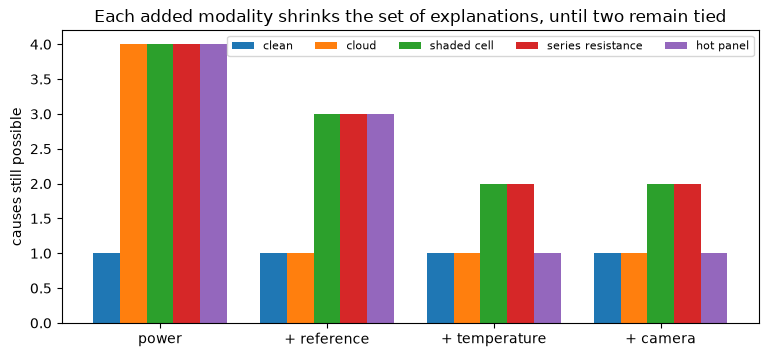

In [4]:
signature = {w: {m: abs(x) >= CHANGED for m, x in zip(MODALITIES, row)} for w, row in zip(WORLDS, change)}


def candidates(observed_world, modalities):
    """Causes whose signature matches the observed world's on the given modalities."""
    return [w for w in WORLDS if all(signature[w][m] == signature[observed_world][m] for m in modalities)]


ORDER = ["power_w", "reference_w_m2", "temperature_c"] + (["camera"] if RENDER else [])
steps = [ORDER[:k] for k in range(1, len(ORDER) + 1)]
print(f"{'modalities used':44s}" + "".join(f"{w:>19s}" for w in WORLDS))
for used in steps:
    label = " + ".join(SHORT[m] for m in used)
    print(f"{label:44s}" + "".join(f"{len(candidates(w, used)):>19d}" for w in WORLDS))

fig, ax = plt.subplots(figsize=(9, 3.8))
width = 0.8 / len(WORLDS)
for k, w in enumerate(WORLDS):
    counts = [len(candidates(w, used)) for used in steps]
    ax.bar(np.arange(len(steps)) + k * width, counts, width, label=w)
ax.set_xticks(np.arange(len(steps)) + 0.4 - width / 2,
              [("+ " if len(s) > 1 else "") + SHORT[s[-1]] for s in steps])
ax.set_ylabel("causes still possible")
ax.set_title("Each added modality shrinks the set of explanations, until two remain tied")
ax.legend(fontsize=8, ncol=5, loc="upper right")
show(fig, "21_candidates")

With the electrical channel alone, a faulty world has four possible causes.
The reference sensor removes the cloud from the list, or confirms it. The
temperature sensor removes the hot panel. The camera adds nothing here that the
reference sensor had not already said, and that is an honest result too: a
modality earns its cost only when it carries information the others do not.
It would start earning it the moment shading became visible, or the reference
sensor failed and needed a cross-check.

Whatever we do passively, two causes remain tied. To separate them we must
*do* something.

## Part 3. Sensing is also an action

The IV curve is a fingerprint. We can only read it by changing the operating
voltage, which costs budget and energy while we are away from the best point.
Six points in two probe actions are enough here. We compare each world's
curve with the clean one, point by point.

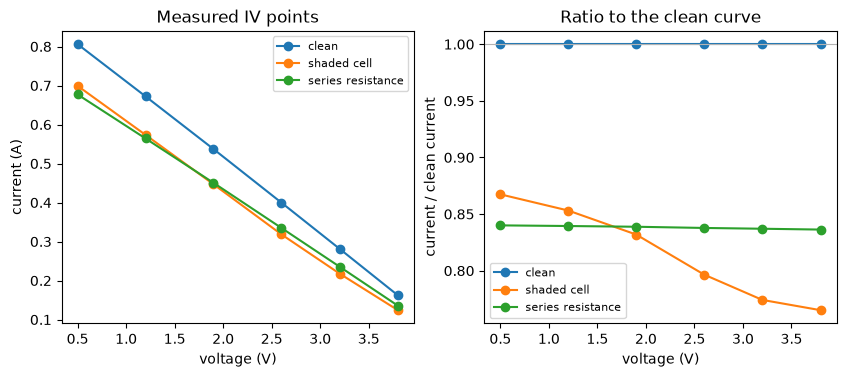

shaded cell        ratio from 0.867 at 0.5 V to 0.765 at 3.8 V; spread 0.102
series resistance  ratio from 0.840 at 0.5 V to 0.836 at 3.8 V; spread 0.004


In [5]:
PROBES = ((0.5, 1.2, 1.9), (2.6, 3.2, 3.8))


def iv_sweep(config):
    """Two probe actions; read the matched V/I from each dwell's feedback."""
    s = Session(config, render=False)
    try:
        s.do("wait", duration_s=0.5, timeout_s=1.0)
        points = {}
        for volts in PROBES:
            observation = s.do("probe_voltage", voltages_v=volts, dwell_s=0.4, timeout_s=8.0)
            for f in observation.feedback:
                if f.code == "executing":
                    v = [m.sample.value for m in f.measured_confirmation if m.sample.channel == "voltage_v"]
                    i = [m.sample.value for m in f.measured_confirmation if m.sample.channel == "current_a"]
                    if v and i:
                        points[round(v[-1], 2)] = i[-1]
        return points, s.env.metrics()
    finally:
        s.close()


curves = {w: iv_sweep(make_config(**WORLDS[w]))[0] for w in ("clean", "shaded cell", "series resistance")}
volts = sorted(curves["clean"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for w, pts in curves.items():
    axes[0].plot(volts, [pts[v] for v in volts], "o-", label=w)
    axes[1].plot(volts, [pts[v] / curves["clean"][v] for v in volts], "o-", label=w)
axes[0].set_xlabel("voltage (V)"); axes[0].set_ylabel("current (A)"); axes[0].set_title("Measured IV points")
axes[1].set_xlabel("voltage (V)"); axes[1].set_ylabel("current / clean current"); axes[1].set_title("Ratio to the clean curve")
axes[1].axhline(1, color="0.7", lw=0.8)
for ax in axes:
    ax.legend(fontsize=8)
show(fig, "22_iv_fingerprint")

for w in ("shaded cell", "series resistance"):
    ratio = [curves[w][v] / curves["clean"][v] for v in volts]
    print(f"{w:18s} ratio from {ratio[0]:.3f} at {volts[0]} V to {ratio[-1]:.3f} at {volts[-1]} V; spread {max(ratio) - min(ratio):.3f}")

The two curves that were indistinguishable at 1.8 V are different in shape. The
series resistance scales the whole curve by about the same factor. The shaded
cell loses proportionally more at high voltage, where its bypass path stops
helping. A spread of the ratio across the sweep above about 0.05 says
"transmission"; a flat ratio says "electrical". (The exact shapes belong to this
surrogate model; a real module has its own fingerprints. The method, compare an
active measurement with a commissioned curve, is the same.)

This is the point of calling sensing an action. The probe bought information
that no passive channel held, and it had a price: six voltage points and the
energy lost while visiting them. Whether to pay is a decision, and that
decision is what the agent loop is for.

## Part 4. What is the agent loop?

```
            ┌──────────────────────────────────────────────────────┐
            │                                                      │
   observe ─┴─► believe ──► decide ──► act ──► verify ──► finish ──┘
   (all          (which      (more         (change    (did it      (say what you
   modalities)   causes      evidence,     voltage,   do what      believe, what
                 fit?)       or act,       move,      you          you tested,
                             or stop?)     probe)     expected?)   what is open)
```

The simulator enforces the loop's shape: one action per decision, feedback
with measured confirmation, a verification tail before `finish`, and a
`Decision` record that must cite evidence and name its hypotheses. What the
loop *contains* is up to the policy. Below is the generic runner, then three
controllers that differ only in what they put in the "believe" and "decide"
boxes.

In [6]:
def run(config, policy, render=False):
    """The loop. Fifteen lines; everything else in this notebook is content."""
    env = PVEnv(config, enable_rendering=render)
    try:
        task, observation = env.reset(seed=1)
        history, decisions = [observation], []
        runner = PolicyRunner(policy, task)          # policy sees public JSON only
        while not history[-1].terminal:
            decision = runner.decide(tuple(history))  # observe → believe → decide
            decisions.append(decision)
            history.append(env.step(decision.action))  # act; the world answers
        return history, decisions, env.metrics()
    finally:
        env.close()


def finish_with_belief(policy, history, probabilities, untested, rationale):
    """A finish decision that states a belief: probabilities over all classes, open questions listed."""
    labels = policy.task.hypothesis_classes
    total = sum(probabilities.get(h, 0.0) for h in labels)
    action = ACTION_ADAPTER.validate_python(dict(schema_version="1.0", action_id=policy.next_action_id,
                                                 kind="finish", timeout_s=2.0, resolution="unresolved" if untested else "resolved"))
    decision = Decision(
        schema_version="1.0", action=action, predictions=(),
        hypothesis_probabilities=tuple(HypothesisProbability(hypothesis=h, probability=probabilities.get(h, 0.0) / total)
                                       for h in labels),
        unresolved_hypotheses=tuple(h for h in labels if h in untested),
        evidence_refs=tuple(o.sequence_id for o in history[-3:]),
        rationale=rationale[:1000],
    )
    validate_decision_context(decision, policy.task, history)
    policy.next_action_id += 1
    policy.pending = action
    policy.stage = "finished"
    return decision


def commission(render):
    """What a commissioning engineer would record on the clean plant: passive readings and the IV curve."""
    passive = passive_look(make_config())
    iv, _ = iv_sweep(make_config())
    return {"P": passive["power_w"], "G": passive["reference_w_m2"], "T": passive["temperature_c"],
            "B": passive.get("camera"), "iv": iv}


COMMISSIONED = commission(RENDER)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in COMMISSIONED.items() if k != "iv"})

{'P': 1.006, 'G': 900.0, 'T': 27.035, 'B': 44.782}


### Controller A: the fixed rule
Hold the nominal voltage, say nothing. This is the open-loop baseline: the
"believe" and "decide" boxes are empty.

In [7]:
class FixedRule(PublicBaseline):
    def act(self, history):
        if self.stage == "start":
            self.stage = "hold"
            return self._emit(history, "set_voltage", "Hold the nominal point.", voltage_v=1.8)
        remaining = history[-1].remaining_budgets.time_s
        if remaining <= 2.5:
            return finish_with_belief(self, history, {h: 1 for h in self.task.hypothesis_classes},
                                      untested=set(self.task.hypothesis_classes), rationale="Held; nothing investigated.")
        d = min(3.0, remaining - 2.4)
        return self._emit(history, "wait", "Hold.", duration_s=d, timeout_s=d + 0.1)

### Controller B: the smart threshold
This is what most monitoring systems do: compare power with a baseline, raise a
fault when it drops. It has a "believe" box with one fixed belief (shading is
the usual suspect) and no "verify" box. It is fast, cheap and confident.

In [8]:
class SmartThreshold(PublicBaseline):
    def __init__(self, commissioned):
        self.c = commissioned

    def act(self, history):
        if self.stage == "start":
            self.stage = "listen"
            return self._emit(history, "wait", "Listen for one second.", duration_s=1.0, timeout_s=1.5)
        P = recent(history, "power_w")
        if P < 0.9 * self.c["P"]:
            return finish_with_belief(self, history, {"transmission_change": 1.0}, untested=set(),
                                      rationale=f"Power {P:.2f} W below 90 % of baseline: shading fault raised.")
        return finish_with_belief(self, history, {h: 1 for h in self.task.hypothesis_classes},
                                  untested=set(self.task.hypothesis_classes), rationale="Power nominal.")

### Controller C: the agent loop
Same sensors, same budget. The difference is in the boxes:

- **believe**: the signature rule from Part 2, over every passive modality;
- **decide**: if one cause fits, verify it; if two fit, check the budget and
  pay for the probe from Part 3; if the irradiance explains only part of the
  loss, keep investigating the remainder;
- **finish**: probabilities over all five classes, and an explicit list of what
  was *not* tested, so "resolved" is never claimed for free.

In [9]:
class AgentLoop(PublicBaseline):
    def __init__(self, commissioned, spread_threshold=0.05):
        self.c = commissioned
        self.spread_threshold = spread_threshold
        self.trace = []            # the belief after each step, for the reader

    def reset(self, task):
        super().reset(task)
        self.points = {}
        self.probe_index = 0

    # --- believe -----------------------------------------------------------
    def passive_belief(self, history):
        P, G, T = (recent(history, m) for m in ("power_w", "reference_w_m2", "temperature_c"))
        B = brightness(history) if "rgb" in self.task.sensors else None
        moved = lambda x, x0: x is not None and x0 is not None and abs(x - x0) / x0 >= CHANGED / 100  # noqa: E731
        belief = {"power_down": moved(P, self.c["P"]) and P < self.c["P"],
                  "irradiance_down": moved(G, self.c["G"]) and G < self.c["G"],
                  "temperature_up": moved(T, self.c["T"]) and T > self.c["T"],
                  "image_darker": moved(B, self.c["B"]) and B < self.c["B"] if B is not None else None,
                  "irradiance_explains_power": None}
        if belief["irradiance_down"]:
            expected = self.c["P"] * G / self.c["G"]
            belief["irradiance_explains_power"] = P >= 0.9 * expected
        return belief, (P, G, T, B)

    def iv_spread(self):
        """Spread of measured/commissioned current ratio across the sweep (irradiance-corrected)."""
        G = self.last_G
        ratios = [self.points[v] / (self.c["iv"][v] * G / self.c["G"]) for v in self.points if v in self.c["iv"]]
        return max(ratios) - min(ratios) if len(ratios) >= 4 else None

    # --- decide --------------------------------------------------------------
    def act(self, history):
        if history[-1].terminal:
            return self._stop(history, "Episode already terminal.")
        if self.stage == "start":
            self.stage = "frame" if "rgb" in self.task.sensors else "listen"
            if self.stage == "frame":
                return self._emit(history, "capture_rgb", "Look at the panel once.", timeout_s=2.0)
            return self._emit(history, "wait", "Listen for one second.", duration_s=1.0, timeout_s=1.5)
        if self.stage == "frame":
            self.stage = "listen"
            return self._emit(history, "wait", "Listen for one second.", duration_s=1.0, timeout_s=1.5)
        if self.stage == "listen":
            belief, (P, G, T, B) = self.passive_belief(history)
            self.last_G = G
            self.trace.append(("passive", belief))
            if not belief["power_down"]:
                return finish_with_belief(self, history, {h: 1 for h in self.task.hypothesis_classes},
                                          untested=set(self.task.hypothesis_classes), rationale="No deviation from the commissioned state.")
            if belief["temperature_up"]:
                return finish_with_belief(self, history, {"thermal_change": 0.8, "electrical_change": 0.1, "transmission_change": 0.1},
                                          untested={"transmission_change", "electrical_change"},
                                          rationale=f"Temperature {T:.1f} °C against {self.c['T']:.1f} °C commissioned with irradiance unchanged: thermal change. A simultaneous transmission or electrical change was not tested.")
            if belief["irradiance_down"] and belief["irradiance_explains_power"]:
                return finish_with_belief(self, history, {"source_change": 0.85, "transmission_change": 0.05, "electrical_change": 0.05, "thermal_change": 0.05},
                                          untested={"transmission_change", "electrical_change"},
                                          rationale=f"Reference irradiance {G:.0f} W/m² explains the power loss within 10 %: source change. Small additional losses were not tested.")
            # Two or more causes still fit. Is the probe affordable?
            if history[-1].remaining_budgets.voltage_points < 6 or history[-1].remaining_budgets.time_s < 10:
                return finish_with_belief(self, history, {"transmission_change": 0.4, "electrical_change": 0.4, "source_change": 0.1, "thermal_change": 0.1},
                                          untested={"transmission_change", "electrical_change"},
                                          rationale="Power loss not explained by irradiance or temperature; probe unaffordable, so the cause stays open.")
            self.stage = "probe"
            why = "irradiance explains only part of the loss" if belief["irradiance_down"] else "passive senses cannot separate shading from an electrical change"
            return self._emit(history, "probe_voltage", f"Pay for an IV sweep: {why}.",
                              voltages_v=PROBES[0], dwell_s=0.4, timeout_s=8.0)
        if self.stage == "probe":
            for f in history[-1].feedback:
                if f.code == "executing" and f.action_id == self.pending.action_id:
                    v = [m.sample.value for m in f.measured_confirmation if m.sample.channel == "voltage_v"]
                    i = [m.sample.value for m in f.measured_confirmation if m.sample.channel == "current_a"]
                    if v and i:
                        self.points[round(v[-1], 2)] = i[-1]
            self.probe_index += 1
            if self.probe_index < len(PROBES):
                return self._emit(history, "probe_voltage", "Second half of the IV sweep.",
                                  voltages_v=PROBES[self.probe_index], dwell_s=0.4, timeout_s=8.0)
            self.stage = "verify"
            return self._emit(history, "wait", "Back at the nominal point; collect fresh V/I before finishing.",
                              duration_s=0.5, timeout_s=1.0)
        if self.stage == "verify":
            spread = self.iv_spread()
            self.trace.append(("iv spread", spread))
            cloud_too = self.trace[0][1]["irradiance_down"]
            if spread is None:
                return finish_with_belief(self, history, {"transmission_change": 0.45, "electrical_change": 0.45, "source_change": 0.05, "thermal_change": 0.05},
                                          untested={"transmission_change", "electrical_change"}, rationale="The sweep did not return enough matched points.")
            found = "transmission_change" if spread >= self.spread_threshold else "electrical_change"
            other = "electrical_change" if found == "transmission_change" else "transmission_change"
            shape = ("voltage-dependent loss, consistent with a shaded or soiled cell" if found == "transmission_change"
                     else "uniform scaling of the curve, consistent with an electrical change")
            if cloud_too:
                belief = {"source_change": 0.45, found: 0.45, other: 0.05, "thermal_change": 0.05}
                text = (f"Two causes: reference irradiance fell (source change) and, after correcting for it, "
                        f"the IV ratio spread is {spread:.3f}: {shape}.")
            else:
                belief = {found: 0.8, other: 0.1, "source_change": 0.05, "thermal_change": 0.05}
                text = f"IV ratio spread {spread:.3f} across the sweep: {shape}."
            return finish_with_belief(self, history, belief, untested=set(), rationale=text)
        return self._stop(history, "Unknown stage.")

## Part 5. Why the agent loop matters

Run all three controllers in the five worlds, plus a **surprise** that none of
them was written for: a cloud *and* a shaded cell at the same time. Score each
controller by the probability it placed on the true cause, whether it claimed
to be resolved, and what it spent.

In [10]:
TEST_WORLDS = dict(WORLDS)
TEST_WORLDS["cloud + shaded cell"] = {"dni_w_m2": 300.0, "transmission": [1, 1, 0.3, 1, 1, 1, 1, 1]}
TEST_TRUTH = dict(TRUTH)
TEST_TRUTH["cloud + shaded cell"] = ("source_change", "transmission_change")

CONTROLLERS = {"A fixed rule": lambda: FixedRule(),
               "B smart threshold": lambda: SmartThreshold(COMMISSIONED),
               "C agent loop": lambda: AgentLoop(COMMISSIONED)}


def score(decision, truth):
    probs = {h.hypothesis: h.probability for h in decision.hypothesis_probabilities}
    if truth is None:
        return 1.0 if decision.action.resolution == "unresolved" and len(set(probs.values())) == 1 else 0.0
    truths = truth if isinstance(truth, tuple) else (truth,)
    return min(probs[t] for t in truths)   # a two-cause world needs both causes believed


results = []
for world, private in TEST_WORLDS.items():
    for name, build in CONTROLLERS.items():
        policy = build()
        history, decisions, metrics = run(make_config(**private), policy, render=RENDER and name.startswith("C"))
        final = decisions[-1]
        strong = [h.hypothesis for h in final.hypothesis_probabilities if h.probability >= 0.3]
        results.append(dict(world=world, controller=name, truth=TEST_TRUTH[world],
                            claim=" + ".join(strong) if strong else "none",
                            mean_power=metrics["pv_energy_j"] / metrics["elapsed_s"],
                            p_truth=score(final, TEST_TRUTH[world]),
                            resolution=final.action.resolution, open=len(final.unresolved_hypotheses),
                            energy=metrics["pv_energy_j"], points=metrics["voltage_points"],
                            frames=metrics["rgb_frames"], decisions=len(decisions), rationale=final.rationale))

print(f"{'world':22s}{'controller':20s}{'claims':40s}{'truth':36s}{'p(truth)':>9s}{'resolution':>12s}{'open':>5s}{'mean W':>8s}{'pts':>4s}")
for r in results:
    truth = r["truth"] if isinstance(r["truth"], str) else " + ".join(r["truth"]) if r["truth"] else "nothing wrong"
    print(f"{r['world']:22s}{r['controller']:20s}{r['claim']:40s}{truth:36s}{r['p_truth']:9.2f}{r['resolution']:>12s}{r['open']:5d}{r['mean_power']:8.3f}{r['points']:4d}")

world                 controller          claims                                  truth                                p(truth)  resolution open  mean W pts
clean                 A fixed rule        none                                    nothing wrong                            1.00  unresolved    5   0.986   1
clean                 B smart threshold   none                                    nothing wrong                            1.00  unresolved    5   1.005   0
clean                 C agent loop        none                                    nothing wrong                            1.00  unresolved    5   1.005   0
cloud                 A fixed rule        none                                    source_change                            0.20  unresolved    5   0.432   1
cloud                 B smart threshold   transmission_change                     source_change                            0.00    resolved    0   0.436   0
cloud                 C agent loop        source_change   

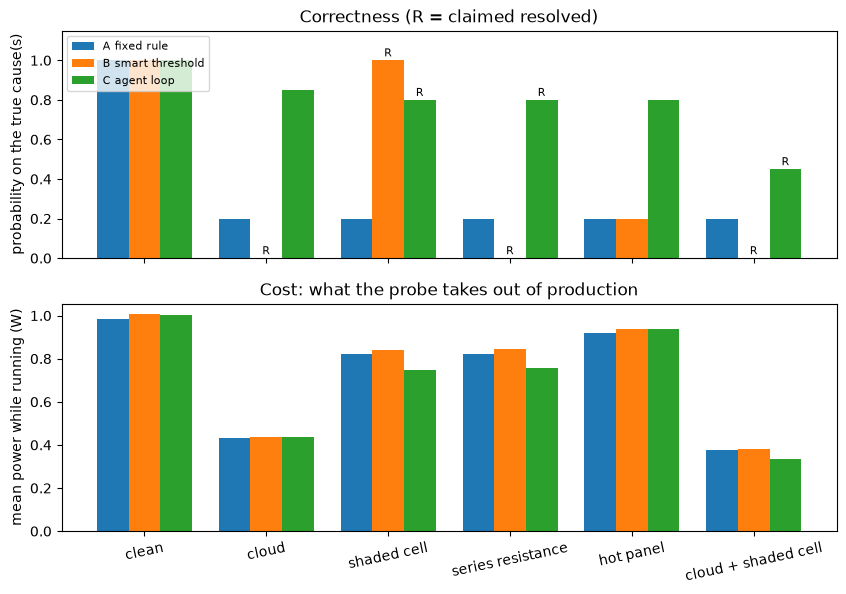

In [11]:
worlds = list(TEST_WORLDS)
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
width = 0.26
for k, name in enumerate(CONTROLLERS):
    rows = [r for r in results if r["controller"] == name]
    x = np.arange(len(worlds)) + (k - 1) * width
    bars = axes[0].bar(x, [r["p_truth"] for r in rows], width, label=name)
    for b, r in zip(bars, rows):
        if r["resolution"] == "resolved":
            axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, "R", ha="center", fontsize=8)
    axes[1].bar(x, [r["mean_power"] for r in rows], width, label=name)
axes[0].set_ylabel("probability on the true cause(s)")
axes[0].set_ylim(0, 1.15)
axes[0].set_title("Correctness (R = claimed resolved)")
axes[1].set_ylabel("mean power while running (W)")
axes[1].set_title("Cost: what the probe takes out of production")
axes[1].set_xticks(range(len(worlds)), worlds, rotation=12)
axes[0].legend(fontsize=8, loc="upper left")
show(fig, "23_controllers")

**What the comparison shows.**

- **A** is never wrong and never useful. It holds a possibly bad operating
  point for the whole episode and reports nothing.
- **B** is right exactly when the usual suspect is the culprit. Under the cloud
  it raises a *false* fault, on the series resistance it names the *wrong*
  fault, on the hot panel it misses the fault entirely because the power loss
  sits under its threshold, and whenever it speaks it says "resolved". A
  confident wrong answer is the most expensive outcome in a real plant, because
  someone acts on it.
- **C** spends more decisions and, when it probes, some production. In return
  it is right in every single-cause world, it lists what it did not test, and
  in the surprise world it notices that the irradiance explains only part of
  the loss, pays for the sweep, and names both causes (0.45 each, which is why
  its bar is lower there: the score needs both to be believed). It was not written for
  that case; the loop handled it because belief, evidence and verification are
  separate steps rather than one rule.

Note the cost panel: the probe lowers mean power during the episode, which is
the price of the diagnosis. Whether that price is worth paying depends on what
the diagnosis is used for, which is a question for the experiment, not the
notebook.

Read the agent's own account of the surprise:

In [12]:
for r in results:
    if r["world"] == "cloud + shaded cell" and r["controller"].startswith("C"):
        print(r["rationale"])
agent = AgentLoop(COMMISSIONED)
_, decisions, _ = run(make_config(**TEST_WORLDS["cloud + shaded cell"]), agent, render=RENDER)
for kind, value in agent.trace:
    print(kind, "→", value)
print([d.action.kind for d in decisions])

Two causes: reference irradiance fell (source change) and, after correcting for it, the IV ratio spread is 0.259: voltage-dependent loss, consistent with a shaded or soiled cell.


passive → {'power_down': True, 'irradiance_down': True, 'temperature_up': False, 'image_darker': True, 'irradiance_explains_power': False}
iv spread → 0.25905934077094783
['capture_rgb', 'wait', 'probe_voltage', 'probe_voltage', 'wait', 'finish']


## What to take away

1. **Multi-modality is about independence, not quantity.** A sense is worth
   having when its signature differs across the causes you care about. Here the
   reference sensor and the temperature sensor each remove one cause; the
   camera removes none until shading is visible; the IV probe removes the last
   ambiguity and is the only sense that costs something.
2. **The agent loop is the discipline that turns senses into decisions.**
   Believe from all the evidence, buy more only when it changes the answer,
   act within limits, verify, and finish with a statement that distinguishes
   what was shown from what was assumed.
3. **The difference shows up under surprise.** Rules are right in the worlds
   they were written for. The loop is also right, or honestly uncertain, in
   the ones they were not.

**Where the minimal goal starts.** Make shading visible to the camera, so the
image becomes a diagnostic modality rather than a duplicate of the reference
sensor. Replace the signature rule with a calibrated model so smaller faults
are caught. Write the agent as a policy behind the same runner, scored by the
same evaluator as the three controllers above.

**Where the stretch goals start.** Add the out-of-list causes (soiling, an
animal, a loose connector, a failed reference sensor) and an "unlisted cause"
answer, and see which controller still behaves. Then give the agent a goal in
words and compare it with a general language-model agent holding the same tools.